# F00 — Recurrence-frontloading-only classifier: OG versus NS10

Use the **same regular RAID dataset and split membership as frozen C05 Ghostbuster**, fitting on training rows with defined F. Freeze one scalar-F classifier before scoring original RAID AI (OG) and final NS10 on common eligible sources from the 54-case cohort. No NS10 examples enter training or calibration.

The exact historical `00b_compute_recurrence_frontloading_with_03b_verification.ipynb` extractor is embedded below (Git blob `441361f043adae8808b339692f04b49442c5135b`). F = mean near-bin excess recurrence minus mean far-bin excess recurrence. It uses a decoded 384-token Qwen3-0.6B-Base prefix, NLTK sentences, content-word-set Jaccard overlap, fixed approximate token-center slots, and 200 sentence-set permutations with seed 42. Finite bins are averaged within each band as in 00b. Missing bands yield undefined F, never zero.

**Eligibility:** the data universe and original splits match C05; actual fitted/scored rows may be fewer because F requires 384 tokens and usable near/far bins. Exclusions and bin support are saved explicitly. We do not silently shorten the prefix or impute missing F. The classifier sees only F: no length, genre, missingness, or Ghostbuster feature coordinates.

The model is a train-scaled logistic regression (C=1), with five-fold sigmoid calibration, fixed before evaluation. It tests a linear decision boundary in scalar F. Raw distributions and paired changes are also reported because classifier performance alone is not evidence that F moved toward human values. This experiment is a development-cohort diagnostic, not an independent final holdout.

Run from the reproduction project or its experiments directory. Only a tokenizer is loaded; no LM weights, GPU generation, or likelihood scoring is required. Per-text feature checkpoints and the fitted model resume on rerun.

In [1]:
from pathlib import Path
import os, re, json, hashlib, tempfile, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, nltk, transformers
from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_curve, auc
from transformers import AutoTokenizer
from IPython.display import display

ROOT=next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents]
    if (p/'results/causal/C05_Ghostbuster_RAID_fixed54').exists()),None)
assert ROOT is not None, 'Run inside the reproduction project.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
C05=ROOT/'results/causal/C05_Ghostbuster_RAID_fixed54'
NSDIR=ROOT/'results/causal/C06b_NEW_steps5_10_v1'
OUT=ROOT/'results/causal/F00_F_only_OG_NS10_v1'
OUT.mkdir(parents=True,exist_ok=True)
CACHE=OUT/'cache'; CACHE.mkdir(exist_ok=True)
SEED=20260921
TOKENIZER_NAME='Qwen/Qwen3-0.6B-Base'
PREFIX_LEN=384
TOKEN_DISTANCE_BINS=[(0,32),(33,64),(65,96),(97,128),(129,160),(161,192),(193,224),(225,256),(257,320)]
NEAR_TOKEN_BINS=TOKEN_DISTANCE_BINS[:3]; FAR_TOKEN_BINS=TOKEN_DISTANCE_BINS[-3:]
N_SHUFFLES=200; SHUFFLE_SEED=42
WORD_RE=re.compile(r"[a-zA-Z][a-zA-Z'-]*")
STOPWORDS=set(ENGLISH_STOP_WORDS)

def digest(data):return hashlib.sha256(data).hexdigest()
def file_sha(p):return digest(Path(p).read_bytes())
def text_sha(t):return digest(str(t).encode())
def atomic(path,data):
    path=Path(path);fd,tmp=tempfile.mkstemp(dir=path.parent,prefix=path.name+'.',suffix='.tmp')
    try:
        with os.fdopen(fd,'wb') as f:f.write(data);f.flush();os.fsync(f.fileno())
        os.replace(tmp,path)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)
def save_json(obj,p):atomic(p,json.dumps(obj,sort_keys=True,indent=2,allow_nan=False).encode())
def save_csv(df,p):atomic(p,df.to_csv(index=False).encode())
def freeze(obj,p):
    if p.exists():assert json.loads(p.read_text())==obj, f'Contract changed: {p}. Use a new OUT directory.'
    else:save_json(obj,p)

# Saved local tokenizer assets fix tokenization across resumed runs.
TOKDIR=OUT/'tokenizer'
if (TOKDIR/'tokenizer_config.json').exists():
    tokenizer=AutoTokenizer.from_pretrained(TOKDIR,local_files_only=True)
else:
    tokenizer=AutoTokenizer.from_pretrained(TOKENIZER_NAME)
    TOKDIR.mkdir(exist_ok=True);tokenizer.save_pretrained(TOKDIR)
try:sent_tokenize('A test sentence. Another test sentence.')
except LookupError:
    nltk.download('punkt',quiet=True);nltk.download('punkt_tab',quiet=True)
    sent_tokenize('A test sentence. Another test sentence.')
print('F00 output:',OUT)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


F00 output: ../results/causal/F00_F_only_OG_NS10_v1


In [2]:
def qwen_prefix_text(
    text,
    prefix_len=PREFIX_LEN,
):
    ids = tokenizer(
        str(text),
        add_special_tokens=False,
    )["input_ids"]

    if len(ids) < prefix_len:
        return None

    ids = ids[:prefix_len]

    return tokenizer.decode(
        ids,
        skip_special_tokens=True,
    )

def content_words(sentence):
    return {
        w
        for w in WORD_RE.findall(
            sentence.lower()
        )
        if (
            w not in STOPWORDS
            and len(w) >= 3
        )
    }


def sentence_sets_and_centers(text):
    sents = [
        s.strip()
        for s in sent_tokenize(text)
        if s.strip()
    ]

    word_sets = []
    centers = []

    cursor = 0

    for sent in sents:
        ids = tokenizer(
            sent,
            add_special_tokens=False,
        )["input_ids"]

        start = cursor
        end = cursor + len(ids)

        centers.append(
            (start + end) / 2
        )

        word_sets.append(
            content_words(sent)
        )

        cursor = end

    return (
        word_sets,
        np.asarray(
            centers,
            dtype=float,
        ),
    )

def jaccard_matrix(word_sets):
    n = len(word_sets)

    J = np.full(
        (n, n),
        np.nan,
        dtype=np.float64,
    )

    for i in range(n):
        J[i, i] = 1.0
        a = word_sets[i]

        for j in range(i + 1, n):
            b = word_sets[j]
            union = a | b

            value = (
                np.nan
                if not union
                else len(a & b) / len(union)
            )

            J[i, j] = value
            J[j, i] = value

    return J


def bin_pair_indices(centers):
    n = len(centers)
    result = {}

    for lo, hi in TOKEN_DISTANCE_BINS:
        ii = []
        jj = []

        for i in range(n):
            for j in range(i + 1, n):
                distance = (
                    centers[j]
                    - centers[i]
                )

                if lo <= distance <= hi:
                    ii.append(i)
                    jj.append(j)

        result[(lo, hi)] = (
            np.asarray(ii, dtype=np.int32),
            np.asarray(jj, dtype=np.int32),
        )

    return result

def observed_from_matrix(
    J,
    pair_idx,
):
    result = {}

    for b in TOKEN_DISTANCE_BINS:
        ii, jj = pair_idx[b]

        if len(ii) == 0:
            result[b] = np.nan
            continue

        values = J[ii, jj]
        values = values[
            np.isfinite(values)
        ]

        result[b] = (
            float(values.mean())
            if len(values)
            else np.nan
        )

    return result


def shuffled_from_matrix(
    J,
    pair_idx,
    n_shuffles=N_SHUFFLES,
    seed=SHUFFLE_SEED,
):
    n = J.shape[0]

    rng = np.random.default_rng(
        seed
    )

    totals = {
        b: 0.0
        for b in TOKEN_DISTANCE_BINS
    }

    counts = {
        b: 0
        for b in TOKEN_DISTANCE_BINS
    }

    for _ in range(n_shuffles):
        order = rng.permutation(n)

        for b in TOKEN_DISTANCE_BINS:
            ii, jj = pair_idx[b]

            if len(ii) == 0:
                continue

            values = J[
                order[ii],
                order[jj],
            ]

            values = values[
                np.isfinite(values)
            ]

            if len(values):
                totals[b] += float(
                    values.mean()
                )
                counts[b] += 1

    return {
        b: (
            totals[b] / counts[b]
            if counts[b] > 0
            else np.nan
        )
        for b in TOKEN_DISTANCE_BINS
    }

def safe_mean(values):
    values = np.asarray(
        values,
        dtype=float,
    )

    valid = np.isfinite(values)

    if not valid.any():
        return np.nan

    return float(
        values[valid].mean()
    )


def compute_minicache_features(
    raw_text,
):
    prefix_text = qwen_prefix_text(
        raw_text,
        prefix_len=PREFIX_LEN,
    )

    result = {
        "eligible_384": prefix_text is not None,
    }

    if prefix_text is None:
        result["n_sentences"] = np.nan

        for lo, hi in TOKEN_DISTANCE_BINS:
            result[
                f"token_excess_{lo}_{hi}"
            ] = np.nan

        result["near_token_cache"] = np.nan
        result["far_token_cache"] = np.nan
        result["token_frontloading"] = np.nan

        return result

    word_sets, centers = (
        sentence_sets_and_centers(
            prefix_text
        )
    )

    result["n_sentences"] = len(
        word_sets
    )

    if len(word_sets) < 2:
        for lo, hi in TOKEN_DISTANCE_BINS:
            result[
                f"token_excess_{lo}_{hi}"
            ] = np.nan

        result["near_token_cache"] = np.nan
        result["far_token_cache"] = np.nan
        result["token_frontloading"] = np.nan

        return result

    J = jaccard_matrix(word_sets)
    pair_idx = bin_pair_indices(
        centers
    )

    observed = observed_from_matrix(
        J,
        pair_idx,
    )

    shuffled = shuffled_from_matrix(
        J,
        pair_idx,
        n_shuffles=N_SHUFFLES,
        seed=SHUFFLE_SEED,
    )

    for lo, hi in TOKEN_DISTANCE_BINS:
        o = observed[(lo, hi)]
        s = shuffled[(lo, hi)]

        result[
            f"token_excess_{lo}_{hi}"
        ] = (
            o - s
            if (
                np.isfinite(o)
                and np.isfinite(s)
            )
            else np.nan
        )

    near_values = [
        result[
            f"token_excess_{lo}_{hi}"
        ]
        for lo, hi in NEAR_TOKEN_BINS
    ]

    far_values = [
        result[
            f"token_excess_{lo}_{hi}"
        ]
        for lo, hi in FAR_TOKEN_BINS
    ]

    result[
        "near_token_cache"
    ] = safe_mean(
        near_values
    )

    result[
        "far_token_cache"
    ] = safe_mean(
        far_values
    )

    if (
        np.isfinite(
            result["near_token_cache"]
        )
        and np.isfinite(
            result["far_token_cache"]
        )
    ):
        result[
            "token_frontloading"
        ] = (
            result["near_token_cache"]
            - result["far_token_cache"]
        )
    else:
        result[
            "token_frontloading"
        ] = np.nan

    return result


In [3]:
# Resolve the exact C05 data universe through saved doc keys.
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert meta.source_id.is_unique and corpus.source_id.is_unique
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].copy().reset_index(drop=True)
keys=pd.read_parquet(C05/'raid_all_features.parquet',columns=['doc_key']).doc_key
expected='raid::'+raid.source_id.astype(str)
assert keys.is_unique and set(keys)==set(expected), 'C05 dataset mismatch'
raid['text']=raid.source_id.map(corpus.set_index('source_id').text)
assert raid.text.notna().all() and raid.text.astype(str).str.strip().ne('').all()
assert set(raid.split)=={'train','validation','test'}
ns=pd.read_csv(NSDIR/'NS10_texts.csv',keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
assert ns.text.map(text_sha).eq(ns.text_sha).all()
rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'split'].eq('test').all()
assert rm.loc[ns.source_id,'label'].eq(1).all()
assert rm.loc[ns.source_id,'domain'].tolist()==ns.domain.tolist()
og=ns[['case_id','source_id','domain']].copy();og['text']=og.source_id.map(rm.text)

# Pin extractor, tokenizer, data and sentence/stopword resources for resume.
import inspect
extractor_names=['qwen_prefix_text','content_words','sentence_sets_and_centers','jaccard_matrix',
    'bin_pair_indices','observed_from_matrix','shuffled_from_matrix','safe_mean','compute_minicache_features']
# Embedded source is set in the next line by the notebook builder.
EXTRACTOR_SHA='c2e9a63191cbf8c322017ca5977122fe3a6b10b2ee02e71d0d1c05d853dd4b8b'
resource_hashes={}
try:
    punkt=Path(str(nltk.data.find('tokenizers/punkt_tab/english/')))
    resource_hashes={p.name:file_sha(p) for p in sorted(punkt.glob('*')) if p.is_file()}
except LookupError:
    punkt=nltk.data.find('tokenizers/punkt/english.pickle')
    with punkt.open() as f:resource_hashes={'english.pickle':digest(f.read())}
contract=dict(version='F00_v1',seed=SEED,extractor_blob='441361f043adae8808b339692f04b49442c5135b',
    extractor_sha=EXTRACTOR_SHA,tokenizer=TOKENIZER_NAME,prefix=PREFIX_LEN,
    bins=[list(b) for b in TOKEN_DISTANCE_BINS],shuffles=N_SHUFFLES,shuffle_seed=SHUFFLE_SEED,
    near='first 3 finite bins',far='last 3 finite bins',classifier='train-scaled scalar logistic C=1; sigmoid CV5; unit weights',
    sklearn=sklearn.__version__,nltk=nltk.__version__,numpy=np.__version__,transformers=transformers.__version__,
    stopwords_sha=text_sha('\n'.join(sorted(STOPWORDS))),punkt=resource_hashes,
    tokenizer_files={p.name:file_sha(p) for p in sorted(TOKDIR.glob('*')) if p.is_file()},
    inputs={str(p.relative_to(ROOT)):file_sha(p) for p in [BASE/'fz118_paired_features.parquet',
        BASE/'paired_corpus.parquet',C05/'raid_all_features.parquet',C05/'contract.json',NSDIR/'NS10_texts.csv']})
freeze(contract,OUT/'contract.json')
CONTRACT_SHA=text_sha(json.dumps(contract,sort_keys=True))
print('RAID membership matches C05:',raid.groupby(['split','label']).size().to_dict())


RAID membership matches C05: {('test', 0): 138, ('test', 1): 138, ('train', 0): 636, ('train', 1): 636, ('validation', 0): 135, ('validation', 1): 135}


In [4]:
def cached_F(text):
    h=text_sha(text);path=CACHE/(h+'.json')
    if path.exists():
        record=json.loads(path.read_text())
        assert record['text_sha']==h and record['contract']==CONTRACT_SHA
        return record['features']
    r=compute_minicache_features(str(text))
    n_tokens=len(tokenizer(str(text),add_special_tokens=False)['input_ids'])
    r['n_tokens_full']=n_tokens
    r['near_bins_finite']=sum(np.isfinite(r[f'token_excess_{a}_{b}']) for a,b in NEAR_TOKEN_BINS)
    r['far_bins_finite']=sum(np.isfinite(r[f'token_excess_{a}_{b}']) for a,b in FAR_TOKEN_BINS)
    r['status']=('eligible' if np.isfinite(r['token_frontloading']) else
        'shorter_than_384' if n_tokens<384 else 'insufficient_near_or_far_support')
    r={k:(None if isinstance(v,(float,np.floating)) and not np.isfinite(v) else
          v.item() if isinstance(v,np.generic) else v) for k,v in r.items()}
    save_json(dict(text_sha=h,contract=CONTRACT_SHA,features=r),path)
    return r

def extract_frame(frame,name):
    rows=[]
    for i,r in enumerate(frame.itertuples(index=False),1):
        row={k:getattr(r,k) for k in ['case_id','source_id','domain','split','label'] if hasattr(r,k)}
        row.update(text_sha=text_sha(r.text),**cached_F(r.text));rows.append(row)
        if i%50==0:print(f'{name}: {i}/{len(frame)} (per-text checkpoints saved)',flush=True)
    result=pd.DataFrame(rows)
    result['token_frontloading']=pd.to_numeric(result['token_frontloading'],errors='coerce')
    save_csv(result,OUT/(name+'_F_features.csv'))
    return result
R=extract_frame(raid,'RAID')
O=extract_frame(og,'OG');N=extract_frame(ns,'NS10')
coverage=R.groupby(['split','label','status']).size().rename('n').reset_index()
save_csv(coverage,OUT/'RAID_eligibility.csv');display(coverage)
elig=O[['case_id','source_id','domain','status','token_frontloading']].rename(columns={'status':'OG_status','token_frontloading':'OG_F'})
elig=elig.merge(N[['case_id','status','token_frontloading']].rename(columns={'status':'NS10_status','token_frontloading':'NS10_F'}),on='case_id',validate='one_to_one')
elig['included']=np.isfinite(elig.OG_F)&np.isfinite(elig.NS10_F)
save_csv(elig,OUT/'paired54_eligibility.csv')
paired=elig.loc[elig.included].reset_index(drop=True)
assert len(paired)>1, 'Insufficient common support; inspect eligibility CSV. Do not change F silently.'
print(f'Common eligible OG/NS10 cases: {len(paired)}/54')
display(elig.loc[~elig.included])


RAID: 50/1818 (per-text checkpoints saved)
RAID: 100/1818 (per-text checkpoints saved)
RAID: 150/1818 (per-text checkpoints saved)
RAID: 200/1818 (per-text checkpoints saved)
RAID: 250/1818 (per-text checkpoints saved)
RAID: 300/1818 (per-text checkpoints saved)
RAID: 350/1818 (per-text checkpoints saved)
RAID: 400/1818 (per-text checkpoints saved)
RAID: 450/1818 (per-text checkpoints saved)
RAID: 500/1818 (per-text checkpoints saved)
RAID: 550/1818 (per-text checkpoints saved)
RAID: 600/1818 (per-text checkpoints saved)
RAID: 650/1818 (per-text checkpoints saved)
RAID: 700/1818 (per-text checkpoints saved)
RAID: 750/1818 (per-text checkpoints saved)
RAID: 800/1818 (per-text checkpoints saved)
RAID: 850/1818 (per-text checkpoints saved)
RAID: 900/1818 (per-text checkpoints saved)
RAID: 950/1818 (per-text checkpoints saved)
RAID: 1000/1818 (per-text checkpoints saved)
RAID: 1050/1818 (per-text checkpoints saved)
RAID: 1100/1818 (per-text checkpoints saved)
RAID: 1150/1818 (per-text chec

,split,label,status,n
0,test,0,eligible,47
1,test,0,shorter_than_384,91
2,test,1,eligible,43
3,test,1,shorter_than_384,95
4,train,0,eligible,150
5,train,0,shorter_than_384,486
6,train,1,eligible,181
7,train,1,shorter_than_384,455
8,validation,0,eligible,26
9,validation,0,shorter_than_384,109


Common eligible OG/NS10 cases: 12/54


,case_id,source_id,domain,OG_status,OG_F,NS10_status,NS10_F,included
0,gate_0001,ai__raid:af383c6d-11c9-4169-a2fa-58280f83ca96,abstracts,shorter_than_384,NaN,eligible,-0.013473,False
2,gate_0004,ai__raid:f5f280b6-e8c1-4f10-9d16-0e6297e8c730,recipes,shorter_than_384,NaN,eligible,0.043637,False
3,gate_0005,ai__raid:7bd2da2a-4f21-4b84-91a7-2cb37fd80071,reddit,shorter_than_384,NaN,shorter_than_384,NaN,False
5,gate_0015,ai__raid:cfb5728e-c896-4ed5-8173-f39be5ff5f97,abstracts,shorter_than_384,NaN,eligible,0.046578,False
8,gate_0018,ai__raid:6caeff0b-6fa7-4fea-9a48-342fe2d6b83b,recipes,eligible,0.022717,shorter_than_384,NaN,False
9,gate_0019,ai__raid:dc315335-0314-49c5-96b1-3211dc072983,reddit,shorter_than_384,NaN,eligible,0.001328,False
12,gate_0022,ai__raid:4c4676d5-c143-448c-b058-9c360b04d900,abstracts,shorter_than_384,NaN,shorter_than_384,NaN,False
13,gate_0023,ai__raid:7b6ca4a8-9f9f-4ede-a9ce-4d6ca52ac525,books,shorter_than_384,NaN,eligible,-0.011024,False
14,gate_0024,ai__raid:f2eaa471-9b08-4ebd-804a-1c12ad4bdad6,news,shorter_than_384,NaN,eligible,-0.001130,False
15,gate_0025,ai__raid:dab3ef7f-6a54-49f9-9367-e907f0618c82,recipes,shorter_than_384,NaN,eligible,0.009528,False


In [5]:
train=R.split.eq('train')&np.isfinite(R.token_frontloading)
tr=R.loc[train].copy()
assert tr.label.value_counts().min()>=5 and tr.label.nunique()==2
assert tr.token_frontloading.nunique()>1, 'No train-set F variation'
model_path=OUT/'F_only_classifier.pkl'
if model_path.exists():
    with model_path.open('rb') as f:bundle=pickle.load(f)
    assert bundle['contract']==CONTRACT_SHA
    clf=bundle['model'];print('Loaded saved F-only classifier.')
else:
    base=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=5000,random_state=SEED))
    clf=CalibratedClassifierCV(base,method='sigmoid',cv=5)
    with warnings.catch_warnings():
        warnings.filterwarnings('error',category=sklearn.exceptions.ConvergenceWarning)
        clf.fit(tr[['token_frontloading']].to_numpy(),tr.label.to_numpy(int))
    atomic(model_path,pickle.dumps(dict(contract=CONTRACT_SHA,model=clf)))
assert list(clf.classes_)==[0,1]
save_csv(tr[['source_id','domain','label','token_frontloading']],OUT/'training_manifest.csv')
print(f'Fit {len(tr)}/{int(R.split.eq("train").sum())} original RAID train rows with defined F; NS10 excluded.')

def predict_f(v):return clf.predict_proba(np.asarray(v,float).reshape(-1,1))[:,1]
mix=paired.domain.value_counts(normalize=True)
def humans(split):
    q=R.loc[R.split.eq(split)&R.label.eq(0)&R.domain.isin(mix.index)&np.isfinite(R.token_frontloading)].copy()
    count=q.domain.value_counts();assert set(mix.index)<=set(count.index), 'Missing eligible human genre'
    q['weight']=[mix[d]/count[d] for d in q.domain]
    q['AI_score']=predict_f(q.token_frontloading)
    assert np.isclose(q.weight.sum(),1)
    save_csv(q,OUT/(split+'_human_reference.csv'))
    return q
cal=humans('validation');human=humans('test')
paired['OG_AI_score']=predict_f(paired.OG_F);paired['NS10_AI_score']=predict_f(paired.NS10_F)
save_csv(paired,OUT/'paired_scores.csv')

cuts=np.r_[np.inf,np.unique(cal.AI_score)[::-1],-np.inf]
st=pd.DataFrame(dict(threshold=cuts,
    calibration_FPR=[cal.loc[cal.AI_score>c,'weight'].sum() for c in cuts],
    test_FPR=[human.loc[human.AI_score>c,'weight'].sum() for c in cuts]))
rows=[]
for name in ['OG','NS10']:
    ai=paired[name+'_AI_score'].to_numpy();hs=human.AI_score.to_numpy()
    fpr,tpr,_=roc_curve(np.r_[np.zeros(len(hs)),np.ones(len(ai))],np.r_[hs,ai],
        sample_weight=np.r_[human.weight,np.ones(len(ai))/len(ai)],drop_intermediate=False)
    rows.append(dict(stage=name,cases=len(ai),AUROC=auc(fpr,tpr),mean_AI_score=ai.mean(),median_AI_score=np.median(ai)))
    st[name]=[(ai>c).mean() for c in cuts]
summary=pd.DataFrame(rows);display(summary.round(6))
save_csv(summary,OUT/'stage_summary.csv');save_csv(st,OUT/'F00_TPR_staircase.csv')
# Sanity check on the eligible regular RAID test split (distinct from intervention comparison).
rt=R.loc[R.split.eq('test')&np.isfinite(R.token_frontloading)]
from sklearn.metrics import roc_auc_score
print('Regular eligible RAID test AUROC (unweighted):',roc_auc_score(rt.label,predict_f(rt.token_frontloading)))


Fit 331/1272 original RAID train rows with defined F; NS10 excluded.


,stage,cases,AUROC,mean_AI_score,median_AI_score
0,OG,12,0.411188,0.539459,0.539362
1,NS10,12,0.630310,0.546271,0.543436


Regular eligible RAID test AUROC (unweighted): 0.49727857496288963


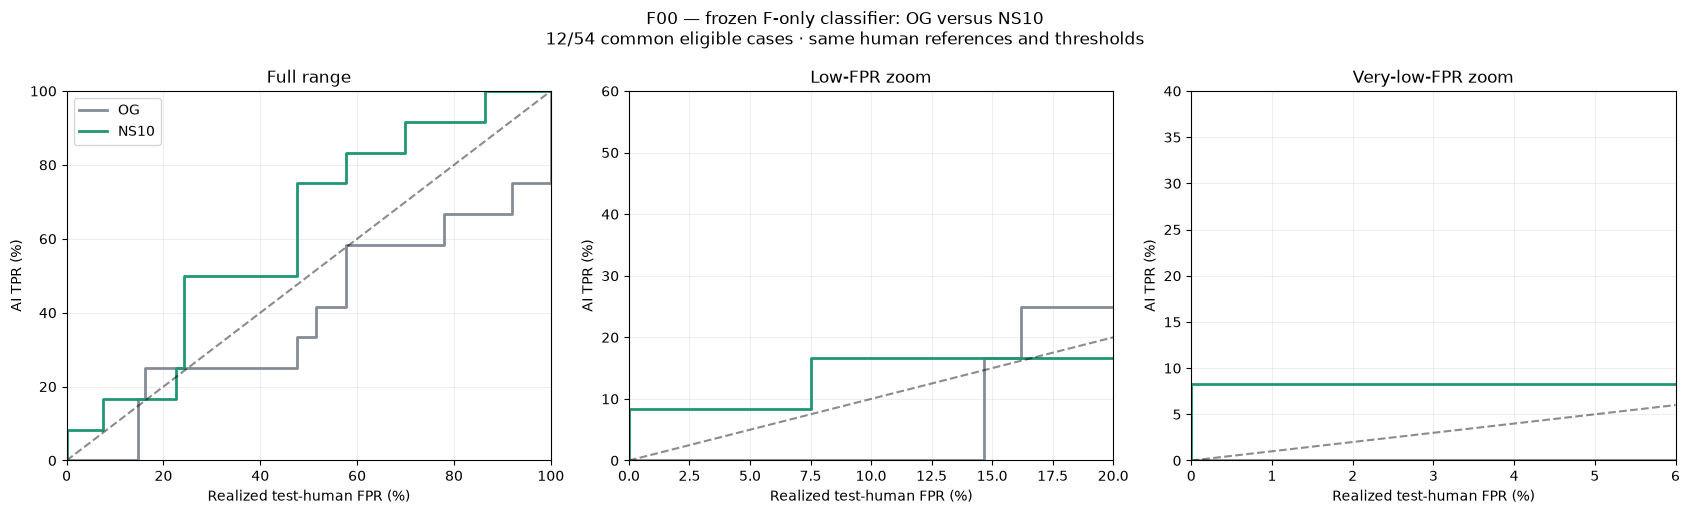

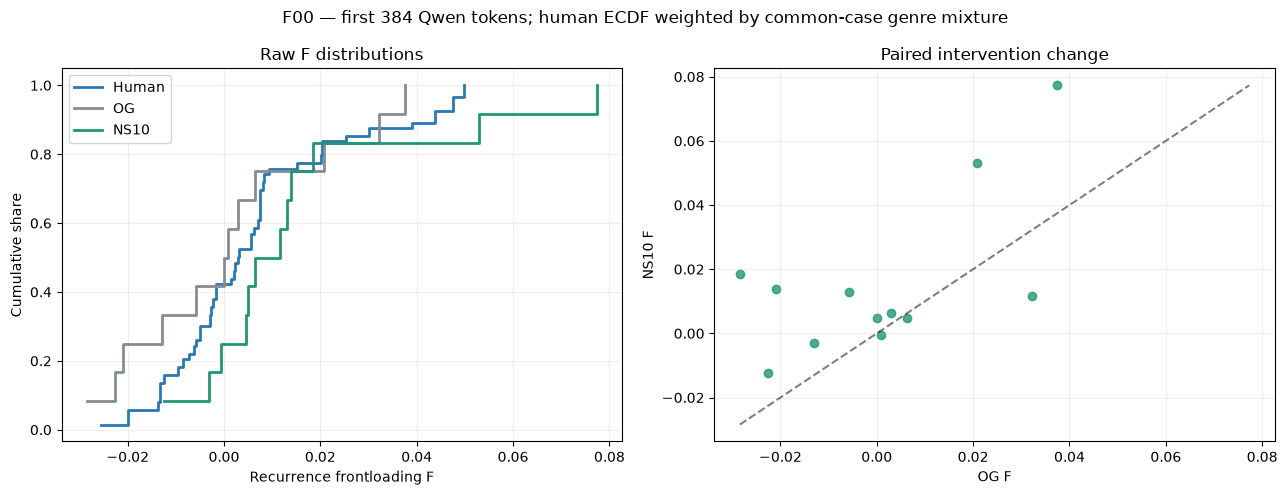

,metric,cases,mean,median,ci_low,ci_high,increased,decreased,unchanged
0,NS10_minus_OG_F,12,0.014749,0.009974,0.004005,0.025465,9,3,0
1,change_in_absolute_distance_to_genre_human_mean,12,-0.000333,-0.003067,-0.010323,0.011046,5,7,0


,stage,cases,mean_F
0,Human,41,0.006450
1,OG,12,0.000839
2,NS10,12,0.015589


Intervals resample paired AI cases with a fixed human reference; no generation-seed or human-sampling uncertainty.
Saved: ../results/causal/F00_F_only_OG_NS10_v1


In [6]:
COLORS={'OG':'#858C96','NS10':'#209675'}
def save_figure(fig,stem):
    for folder in [OUT,ROOT/'figures']:
        folder.mkdir(exist_ok=True,parents=True)
        for ext in ['png','pdf']:fig.savefig(folder/(stem+'.'+ext),dpi=300,bbox_inches='tight')
    plt.show();plt.close(fig)
fig,axs=plt.subplots(1,3,figsize=(17,5.2))
for ax,(xl,yl,title) in zip(axs,[((0,100),(0,100),'Full range'),((0,20),(0,60),'Low-FPR zoom'),((0,6),(0,40),'Very-low-FPR zoom')]):
    for name in COLORS:ax.step(st.test_FPR*100,st[name]*100,where='post',color=COLORS[name],lw=2,label=name)
    hi=min(xl[1],yl[1]);ax.plot([0,hi],[0,hi],'--',color='black',alpha=.45)
    ax.set(xlim=xl,ylim=yl,title=title,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)');ax.grid(alpha=.2)
axs[0].legend()
fig.suptitle(f'F00 — frozen F-only classifier: OG versus NS10\n{len(paired)}/54 common eligible cases · same human references and thresholds')
fig.tight_layout();save_figure(fig,'F00_OG_NS10_TPR_staircase')

# Raw F evidence complements detector ranking; direction is not assumed in advance.
fig,axs=plt.subplots(1,2,figsize=(13,5))
for name,v,w,color in [('Human',human.token_frontloading.to_numpy(),human.weight.to_numpy(),'#2878B5'),
    ('OG',paired.OG_F.to_numpy(),np.ones(len(paired))/len(paired),COLORS['OG']),
    ('NS10',paired.NS10_F.to_numpy(),np.ones(len(paired))/len(paired),COLORS['NS10'])]:
    order=np.argsort(v);axs[0].step(v[order],np.cumsum(w[order]),where='post',label=name,color=color,lw=2)
axs[0].set(xlabel='Recurrence frontloading F',ylabel='Cumulative share',title='Raw F distributions');axs[0].legend()
axs[1].scatter(paired.OG_F,paired.NS10_F,c=COLORS['NS10'],alpha=.8)
lo=min(paired.OG_F.min(),paired.NS10_F.min());hi=max(paired.OG_F.max(),paired.NS10_F.max())
axs[1].plot([lo,hi],[lo,hi],'--',color='black',alpha=.5)
axs[1].set(xlabel='OG F',ylabel='NS10 F',title='Paired intervention change')
for ax in axs:ax.grid(alpha=.2)
fig.suptitle('F00 — first 384 Qwen tokens; human ECDF weighted by common-case genre mixture')
fig.tight_layout();save_figure(fig,'F00_raw_F_distributions_and_pairs')

rng=np.random.default_rng(SEED);ix=rng.integers(0,len(paired),size=(10000,len(paired)))
delta=(paired.NS10_F-paired.OG_F).to_numpy()
human_means=human.groupby('domain').token_frontloading.mean()
ref=human_means.loc[paired.domain].to_numpy()
# Negative distance delta means closer to the same-genre human mean; not distributional equality.
distance_delta=np.abs(paired.NS10_F.to_numpy()-ref)-np.abs(paired.OG_F.to_numpy()-ref)
raw_rows=[]
for name,v in [('NS10_minus_OG_F',delta),('change_in_absolute_distance_to_genre_human_mean',distance_delta)]:
    low,high=np.quantile(v[ix].mean(axis=1),[.025,.975])
    raw_rows.append(dict(metric=name,cases=len(v),mean=v.mean(),median=np.median(v),ci_low=low,ci_high=high,
        increased=int((v>0).sum()),decreased=int((v<0).sum()),unchanged=int((v==0).sum())))
raw_summary=pd.DataFrame(raw_rows);save_csv(raw_summary,OUT/'paired_F_changes.csv');display(raw_summary.round(6))
raw_means=pd.DataFrame([dict(stage='Human',cases=len(human),mean_F=np.average(human.token_frontloading,weights=human.weight)),
    dict(stage='OG',cases=len(paired),mean_F=paired.OG_F.mean()),dict(stage='NS10',cases=len(paired),mean_F=paired.NS10_F.mean())])
save_csv(raw_means,OUT/'raw_F_means.csv');display(raw_means)
print('Intervals resample paired AI cases with a fixed human reference; no generation-seed or human-sampling uncertainty.')
print('Saved:',OUT)


## Reading F00

- **Check eligibility first.** The classifier uses the same C05 data universe and split assignments, but excludes undefined F. The paired staircase includes only cases where both OG and NS10 have defined F. It must not be called a 54-case result unless all 54 qualify.
- A strong OG classifier followed by reduced NS10 detection supports attenuation of this F signal. If the OG classifier is already weak, near-chance NS10 performance alone establishes little about intervention success.
- Inspect the raw F changes, ECDFs, and same-genre human distances. Positive F means *local recurrence relative to distant recurrence*, not information packed into the beginning of a document. Lower F is not automatically more human-like.
- F is the sole detector input. The one-dimensional logistic specification tests a directional relationship; it does not exhaust nonlinear decision rules in F. No classifier family or direction is selected using NS10.
- Earlier development included this source cohort. Results describe the current endpoint, not an independent holdout confirmation or proof of the full theory.

Canonical output: `results/causal/F00_F_only_OG_NS10_v1/`. Preserve `contract.json`, `tokenizer/`, `cache/`, and the classifier to resume. Any future change to F, prefix length, or classifier protocol belongs in a distinct run directory.